# 00 · Step 1: Data health check
**Goal:** prove the 3 X5 files can be trusted *before* any model touches them.

| Check | Question it answers |
|---|---|
| 1a | What is inside each file? |
| 1b | Do the files connect on `client_id`? |
| 1c | Any duplicates? |
| 1d | Any blanks, and do they mean something? |
| 1e | Any junk values (impossible ages, negative bills, odd dates)? |
| 1f | What is the real timeline? |

**How to use:** Run All (or Shift+Enter cell by cell). Cell 0 converts the big purchases file once (2–5 min the first time; instant after). Save with **Ctrl+S** when done.

## Cell 0 · Setup
- Loads the 2 small files with pandas.
- Converts `purchases.csv.gz` (≈45M rows) **once** into a fast Parquet file using DuckDB. DuckDB reads in chunks, so your RAM does not fill up.
- If you see `No module named duckdb`, run `pip install duckdb pyarrow` in the terminal and rerun.

In [ ]:
   %pip install pandas numpy duckdb pyarrow matplotlib

In [2]:
import pandas as pd, numpy as np, duckdb, time
import matplotlib.pyplot as plt
from pathlib import Path
pd.set_option('display.width', 160); pd.set_option('display.max_columns', 30)

RAW = Path('..') / 'data_x5' / 'raw'
PQ  = Path('..') / 'data_x5' / 'parquet'; PQ.mkdir(exist_ok=True)
PURCH_PQ = (PQ / 'purchases.parquet').as_posix()

exp = pd.read_csv(RAW / 'uplift_train.csv.gz')
cli = pd.read_csv(RAW / 'clients.csv.gz', parse_dates=['first_issue_date', 'first_redeem_date'])

con = duckdb.connect()
if not (PQ / 'purchases.parquet').exists():
    t0 = time.time()
    con.sql(f"""
        COPY (SELECT * FROM read_csv('{(RAW / 'purchases.csv.gz').as_posix()}', header=true, columns={{
            'client_id':'VARCHAR','transaction_id':'VARCHAR','transaction_datetime':'TIMESTAMP',
            'regular_points_received':'DOUBLE','express_points_received':'DOUBLE',
            'regular_points_spent':'DOUBLE','express_points_spent':'DOUBLE','purchase_sum':'DOUBLE',
            'store_id':'VARCHAR','product_id':'VARCHAR','product_quantity':'DOUBLE',
            'trn_sum_from_iss':'DOUBLE','trn_sum_from_red':'DOUBLE'}}))
        TO '{PURCH_PQ}' (FORMAT PARQUET)""")
    print(f'converted purchases to parquet in {time.time()-t0:.0f}s')
con.sql(f"CREATE OR REPLACE VIEW pur AS SELECT * FROM '{PURCH_PQ}'")
con.register('exp', exp); con.register('cli', cli)
print('ready')

ready


## 1a · What is inside each file?
**Output:** rows, columns, types and 3 sample rows per file. This becomes the data dictionary in the doc.

In [ ]:
for name, d in [('uplift_train', exp), ('clients', cli)]:
    print(f'=== {name}: {len(d):,} rows x {d.shape[1]} cols'); print(d.dtypes.to_string()); display(d.head(3))

print('=== purchases:', f"{con.sql('SELECT COUNT(*) FROM pur').fetchone()[0]:,} rows")
display(con.sql('DESCRIBE pur').df()[['column_name', 'column_type']])
display(con.sql('SELECT * FROM pur LIMIT 3').df())

## 1b · Do the files connect?
**Idea:** every experiment customer should exist in `clients` and have purchase history. **Expect:** ~100%.

In [4]:
res = con.sql('''
WITH pc AS (SELECT DISTINCT client_id FROM pur)
SELECT
  (SELECT COUNT(*) FROM exp)                                              AS exp_customers,
  (SELECT AVG((client_id IN (SELECT client_id FROM cli))::INT) FROM exp)  AS exp_in_clients,
  (SELECT AVG((client_id IN (SELECT client_id FROM pc))::INT)  FROM exp)  AS exp_in_purchases,
  (SELECT COUNT(*) FROM cli)                                              AS all_clients,
  (SELECT AVG((client_id IN (SELECT client_id FROM pc))::INT)  FROM cli)  AS clients_in_purchases,
  (SELECT COUNT(*) FROM pc)                                               AS customers_with_purchases
''').df().T
res.columns = ['value']; res

,value
exp_customers,200039.0
exp_in_clients,1.0
exp_in_purchases,1.0
all_clients,400162.0
clients_in_purchases,1.0
customers_with_purchases,400162.0


## 1c · Duplicates
- One row per customer in `uplift_train` and `clients`?
- In `purchases`, one row = one product line of one bill. A repeated (bill, product) pair could be a real double line or a data error.
- Bill-level fields (`purchase_sum`, points) should be the **same on every line of a bill**. If true, total spend must be counted once per bill, not summed over lines.

In [5]:
print('duplicate client_id in uplift_train:', exp.client_id.duplicated().sum())
print('duplicate client_id in clients     :', cli.client_id.duplicated().sum())
display(con.sql('''
SELECT
  COUNT(*)                                        AS product_lines,
  COUNT(DISTINCT transaction_id)                  AS bills,
  COUNT(*) - (SELECT COUNT(*) FROM (SELECT DISTINCT transaction_id, product_id FROM pur)) AS repeated_bill_product_lines,
  COUNT(*) - (SELECT COUNT(*) FROM (SELECT DISTINCT * FROM pur))                          AS exact_duplicate_rows
FROM pur''').df().T.rename(columns={0: 'value'}))
display(con.sql('''
SELECT COUNT(*) AS bills,
       SUM((n_sum > 1)::INT)    AS bills_with_varying_purchase_sum,
       SUM((n_client > 1)::INT) AS bills_with_more_than_one_customer
FROM (SELECT transaction_id, COUNT(DISTINCT purchase_sum) n_sum, COUNT(DISTINCT client_id) n_client
      FROM pur GROUP BY 1)''').df().T.rename(columns={0: 'value'}))

duplicate client_id in uplift_train: 0
duplicate client_id in clients     : 0


,value
product_lines,45786568
bills,8045201
repeated_bill_product_lines,3
exact_duplicate_rows,0


,value
bills,8045201.0
bills_with_varying_purchase_sum,28.0
bills_with_more_than_one_customer,28.0


## 1d · Blanks
**Idea:** a blank can be an error **or** a fact. A blank `first_redeem_date` is a fact: the customer never used points.

In [6]:
def blanks(d):
    out = d.isna().sum().to_frame('blank'); out['blank %'] = (100 * out.blank / len(d)).round(2); return out
print('uplift_train'); display(blanks(exp))
print('clients');      display(blanks(cli))
print('purchases')
s = con.sql('SUMMARIZE pur').df()[['column_name', 'null_percentage']]
display(s)

uplift_train


,blank,blank %
client_id,0,0.0
treatment_flg,0,0.0
target,0,0.0


clients


,blank,blank %
client_id,0,0.00
first_issue_date,0,0.00
first_redeem_date,35469,8.86
age,0,0.00
gender,0,0.00


purchases


,column_name,null_percentage
0,client_id,0.00
1,transaction_id,0.00
2,transaction_datetime,0.00
3,regular_points_received,0.00
4,express_points_received,0.00
5,regular_points_spent,0.00
6,express_points_spent,0.00
7,purchase_sum,0.00
8,store_id,0.00
9,product_id,0.00


## 1e · Junk values
**Idea:** find values that cannot be true, count them, and decide a rule (drop, keep, or fix).

In [7]:
print('age outside 14-100:', (~cli.age.between(14, 100)).sum(), 'of', len(cli))
print(cli.age.describe(percentiles=[.01, .05, .5, .95, .99]).round(1).to_string())
print('\ngender values:'); print(cli.gender.value_counts(dropna=False).to_string())
print('\nredeem date BEFORE card issue date:', (cli.first_redeem_date < cli.first_issue_date).sum())
print('card issue range :', cli.first_issue_date.min(), '->', cli.first_issue_date.max())
print('first redeem range:', cli.first_redeem_date.min(), '->', cli.first_redeem_date.max())
display(con.sql('''
SELECT
  SUM((purchase_sum <= 0)::INT)        AS lines_bill_sum_zero_or_negative,
  SUM((product_quantity <= 0)::INT)    AS lines_quantity_zero_or_negative,
  SUM((trn_sum_from_iss < 0)::INT)     AS lines_item_amount_negative,
  SUM((regular_points_spent > 0)::INT) AS lines_points_spent_positive,
  MIN(purchase_sum) AS min_bill, MAX(purchase_sum) AS max_bill,
  MIN(product_quantity) AS min_qty, MAX(product_quantity) AS max_qty
FROM pur''').df().T.rename(columns={0: 'value'}))

age outside 14-100: 1779 of 400162
count    400162.0
mean         46.5
std          43.9
min       -7491.0
1%           17.0
5%           22.0
50%          45.0
95%          72.0
99%          82.0
max        1901.0

gender values:
gender
U    185706
F    147649
M     66807

redeem date BEFORE card issue date: 536
card issue range : 2017-04-04 18:24:18 -> 2019-03-15 21:50:56
first redeem range: 2017-04-11 09:42:20 -> 2019-11-20 01:14:10


,value
lines_bill_sum_zero_or_negative,620.00
lines_quantity_zero_or_negative,2707278.00
lines_item_amount_negative,0.00
lines_points_spent_positive,0.00
min_bill,0.00
max_bill,35149.04
min_qty,0.00
max_qty,14941.00


## 1f · Timeline
**Idea:** when does purchase history start and end? The message went out *after* history ended, and `target` was measured in the window after that.

**Output:** first/last date + a monthly chart of bills and active customers.

,first_purchase,last_purchase
0,2018-11-21 21:02:33,2019-03-18 23:40:03


,month,bills,customers
0,2018-11-01,553287,223449
1,2018-12-01,1979355,329130
2,2019-01-01,1908118,331791
3,2019-02-01,2104788,360005
4,2019-03-01,1499676,377847


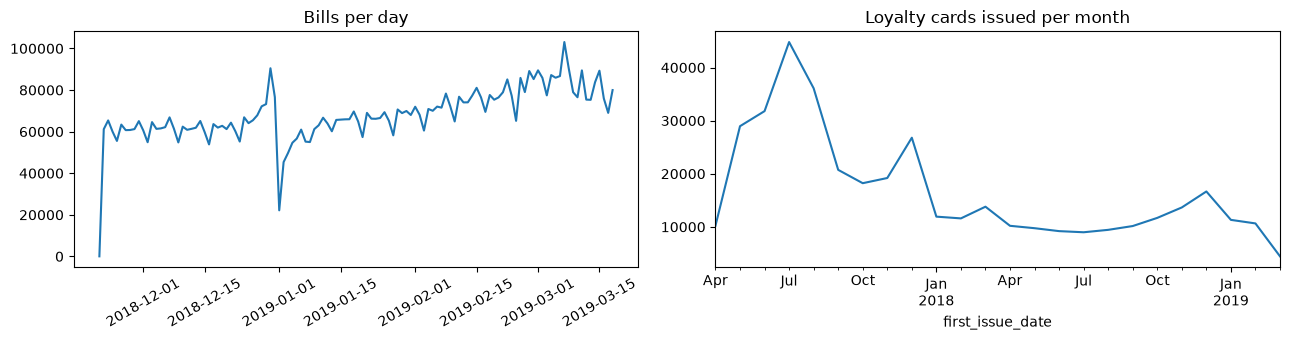

In [8]:
display(con.sql('SELECT MIN(transaction_datetime) first_purchase, MAX(transaction_datetime) last_purchase FROM pur').df())
m = con.sql('''
SELECT date_trunc('month', transaction_datetime) AS month,
       COUNT(DISTINCT transaction_id) AS bills, COUNT(DISTINCT client_id) AS customers
FROM pur GROUP BY 1 ORDER BY 1''').df()
display(m)
d = con.sql('''SELECT CAST(transaction_datetime AS DATE) AS dt, COUNT(DISTINCT transaction_id) AS bills FROM pur GROUP BY 1 ORDER BY 1''').df()

fig, ax = plt.subplots(1, 2, figsize=(13, 3.5))
ax[0].plot(d.dt, d.bills); ax[0].set_title('Bills per day'); ax[0].tick_params(axis='x', rotation=30)
cli.first_issue_date.dt.to_period('M').value_counts().sort_index().plot(ax=ax[1])
ax[1].set_title('Loyalty cards issued per month')
plt.tight_layout(); plt.show()

## Your notes (2–3 lines in your own words)
- Is the data usable?
- Surprises:
- Cleaning rules we need: